<a href="https://colab.research.google.com/github/EsraaMoh/WACAD/blob/main/notebooks/exp_02_WebArchive_Working_With_WARCs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Working with WARC Files


## Overview

This notebook demonstrates how to query and extract web archive data from WARC files using a CDX index. It provides a foundation for working with raw web archive data and accompanying index files.

This notebook uses existing WARC files with pre-generated CDX files, located in an S3 bucket. This S3 bucket has been periodically made public for the use of this notebook in workshops. If the S3 bucket is not longer publically accessible, then this notebook can be reconfigured to point at an alternative endpoint with WARC and CDX data.

Note, some of the code cells contain commented out code for loading CDX and WARC data from local files. To use this, uncomment it, and comment out the equivalent S3 code. This scenario works when running the Jupyter Notebook in a local environment on your device.

### Learning Objectives

1. Understand the roles of WARC and CDX files in web archiving
2. Load and interpret CDX index files
3. Find archived records in WARC files using index metadata
4. Extract textual content from archived web pages

This notebook serves as an introduction to web archive access methods that will be built upon in subsequent notebooks.

## Environment Setup

### Installing Required Python Packages

The following packages are necessary for working with web archives:

In [ ]:
!pip install boto3 s3fs pandas warcio beautifulsoup4


INFO: pip is looking at multiple versions of aiobotocore to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of aiobotocore to determine which version is compatible with other requirements. This could take a while.
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https://pip.pypa.io/warnings/backtracking for guidance. If you want to abort this run, press Ctrl + C.
INFO: pip is looking at multiple versions of s3fs to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of s3fs to determine which version is compatible with other requirements. This could take a while.
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https://pip.pypa.io/warnings/

In [ ]:
!pip install   spacy

In [ ]:
from getpass import getpass
from warcio.archiveiterator import ArchiveIterator   #Reads WARC files
import pandas as pd                                  #Creates data tables
from bs4 import BeautifulSoup                        #Parses HTML text
import boto3                                         #Connects to S3
from botocore.client import Config                   #S3 login configuration

## 1. Accessing WARC Files

<img src="https://ndha-public-data-ap-southeast-2.s3.ap-southeast-2.amazonaws.com/iPRES-2025/resources/warc_cdx_side_by_side_transparent.png" alt="WARC and CDX files" border="0" width="500">

WARC (Web ARChive) files are the standard format for storing web archives. They contain the actual content of archived web pages along with metadata. In this section, we'll explore how to access,list and extract data from WARC files.

> ***Note***
>
> *This section is using a dataset extracted from Common Crawl web archive (CC-NEWS). To ensure accessibility and simulate cloud storage, we have hosted these WARC and CDX files in a local MinIO S3-compatible bucket for the purposes of this workshop*

In [ ]:
URL = input("URL: ")
USERNAME = input("Username: ")
PASSWORD = getpass("Password: ")

In [ ]:
bucket_name = 'warc-data'
cdx_files = []

#Define S3 bucket
s3 = boto3.client(
    's3',
    endpoint_url= URL,
    aws_access_key_id= USERNAME,
    aws_secret_access_key= PASSWORD,
    config=Config(signature_version='s3v4')
)

#Return a dictionary containing the bucket's metadata
response = s3.list_objects_v2(Bucket=bucket_name)
all_files = response.get('Contents', [])

print("Files in bucket:")
for file in all_files:
  print(file['Key'])

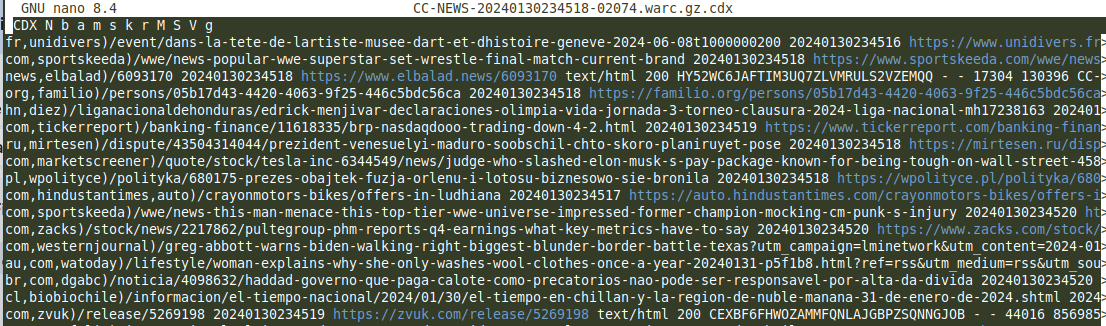

### Understanding CDX Files

CDX (Capture inDeX) files serve as indexes for WARC files, making it easier to locate specific content. They follow a standardized format described in the [CDX documentation](https://iipc.github.io/warc-specifications/specifications/cdx-format/cdx-2015/).

The standard 11-field CDX format includes:

1. **N**: Normalized/massaged URL
2. **b**: Capture date (timestamp)
3. **a**: Original URL
4. **m**: MIME type of the document
5. **s**: HTTP response code
6. **k**: Content checksum
7. **r**: Redirect URL
8. **M**: Meta tags
9. **S**: Compressed record size
10. **V**: Compressed payload offset
11. **g**: Source WARC filename

Let's load a CDX file and examine its structure:

In [ ]:
cdx_file = 'CC-NEWS-20240130234518-02074.warc.gz.cdx'

df = pd.read_csv(f"s3://{bucket_name}/{cdx_file}", sep=" ", skiprows=1, storage_options={
        "key":            USERNAME,
        "secret":         PASSWORD,
        "client_kwargs":  {"endpoint_url": URL},
    })

# Assign column names according to the CDX standard
df.columns = ["N", "b", "a", "m", "s", "k", "r", "M", "S", "V", "g"]

display(df)

### 2. Extracting Content from WARC Files

Using the information from the CDX file (particularly the filename and offset), we can extract html content from a WARC file in S3 bucket using a specific offset.

Extraction steps: get S3 (Bytes) from storage server ➡️ use warcio (Extracts HTML from the WARC record) ➡️ use BeautifulSoup (Extracts Text from the HTML).




In [ ]:
warc_file = 'CC-NEWS-20240129002816-02035.warc.gz'
offset, size = 979984864, 46505

#Get record (bytes size) from S3 bucket
response = s3.get_object(
    Bucket=bucket_name,
    Key=warc_file,
    Range=f"bytes={offset}-{offset+size-1}"
)

#Decompress, read WARC Headers, and read Content-Length
record = next(item for item in ArchiveIterator(response["Body"]) if item.rec_type == 'response')

#Bypass html headers, read html bytes, and decode to text
html_payload = record.content_stream().read().decode('utf-8', errors='replace')

In [ ]:
import requests
url = record.rec_headers.get_header("WARC-Target-URI")
current_html = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}).text

## 3. Processing and Analyzing Web Archive Content

Once we've extracted content from WARC files, we can process and analyze it using various tools. For HTML content, the *BeautifulSoup* Python library is particularly useful for parsing and extracting text.

In [ ]:
#Parse the HTML payload using BeautifulSoup
soup = BeautifulSoup(html_payload, "html.parser")

#Find the main article content
article = soup.find("div", class_="post-body")

#Extract article text
all_text = article.get_text("\n", strip=True) if article else "Article not found"

#print the article
print(all_text)

In [24]:
import requests
from bs4 import BeautifulSoup

# 1. Parse both versions
archived = BeautifulSoup(html_payload, "html.parser")
live = BeautifulSoup(requests.get(record.rec_headers.get_header("WARC-Target-URI")).text, "html.parser")

# 2. Compare Text, Links, and Media
print(f"Archived Words:  {len(archived.get_text().split())} | Live Words:  {len(live.get_text().split())}")
print(f"Archived Links:  {len(archived.find_all('a'))} | Live Links:  {len(live.find_all('a'))}")
print(f"Archived Images: {len(archived.find_all('img'))} | Live Images: {len(live.find_all('img'))}")
print(f"Archived Tables: {len(archived.find_all('table'))} | Live Tables: {len(live.find_all('table'))}")

Archived Words:  8005 | Live Words:  8376
Archived Links:  1060 | Live Links:  1162
Archived Images: 86 | Live Images: 89
Archived Tables: 2 | Live Tables: 2


In [ ]:
import spacy
import matplotlib.pyplot as plt
from collections import Counter

#Extract Entities
nlp = spacy.load("en_core_web_sm")
doc = nlp(all_text)
entities = [ent.text for ent in doc.ents if ent.label_ in ["PERSON", "ORG", "GPE"]]

#Count and Visualize
top_entities = Counter(entities).most_common(8)
labels, values = zip(*top_entities)
plt.barh(labels, values, color='skyblue')
plt.title("Key Entities Mentioned in the Article")
plt.show()

In [ ]:
from textblob import TextBlob

#Pass the text we extracted from the WARC
blob = TextBlob(all_text)

#Polarity is -1 (Negative) to +1 (Positive)
print(f"Sentiment Score: {blob.sentiment.polarity:.2f}")
print("Positive" if blob.sentiment.polarity > 0 else "Negative" if blob.sentiment.polarity < 0 else "Neutral")

Machine learning models cannot read English; they only understand math. This cell takes our messy WARC text, removes the fluff, and converts it into a TF-IDF matrix. The X-axis shows the top 6 predictive features, and the Y-axis shows their mathematical weight. This exact matrix is what you feed into a predictive model to train it to classify whether an article is about 'Politics', 'War', or 'Economics'.

---

## Hands-On Exercise Solutions



### Citation

**Title:** Working with WARC Files (Jupyter notebook)  
**Author:** Yizhe Zhan, Ben O'Brien  
**Affiliation:** National Library of New Zealand, Wellington  
**Last updated:** 2026‑04‑14  

**Contact:** yizhe.git@gmail.com  
**Repository:** https://github.com/NLNZDigitalPreservation/wa-nlnz-toolkit